In [1]:
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge

SEED = 42

# Reload the SAME split as Step 1 (same seed, so identical rows)
from sklearn.model_selection import train_test_split
raw = pd.read_csv("../data/ames_raw.csv").drop(columns=["Id"], errors="ignore")
X = raw.drop(columns=["SalePrice"])
y = raw["SalePrice"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

# DECISION: train on log1p(price). RMSE on this scale equals the Kaggle metric (RMSLE),
# and predictions are converted back with np.expm1 only when reporting dollars.
y_train_log = np.log1p(y_train)

In [2]:
# DECISION: "NA means the feature is absent" columns are filled with "None" BEFORE the pipeline.
# Reason: this is fixed domain knowledge from the data description, not something learned
# from the data, so doing it up front cannot leak information between CV folds.
NONE_COLS = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "MasVnrType"]

def fill_none(df):
    df = df.copy()
    df[NONE_COLS] = df[NONE_COLS].fillna("None")
    return df

X_train = fill_none(X_train)
X_test  = fill_none(X_test)   # same fixed rule, safe to apply to the holdout

In [3]:
# DECISION: all learned steps (imputing, scaling, encoding) live INSIDE a Pipeline.
# Reason: cross_validate refits the whole pipeline on each training fold, so statistics
# such as medians or scaler means never see the validation fold. That prevents leakage.

# DECISION: select columns by dtype instead of hard-coding names, using "exclude number"
# for categoricals (pandas now uses a 'str' dtype, so "object" would miss them).
num_sel = make_column_selector(dtype_include="number")
cat_sel = make_column_selector(dtype_exclude="number")

def make_preprocessor(scale=True):
    # Numeric: median is robust to skew/outliers (LotFrontage, GarageYrBlt, MasVnrArea).
    num_steps: list[tuple[str, object]] = [("impute", SimpleImputer(strategy="median"))]
    # Scaling matters for Ridge (penalty is scale-sensitive) but not for tree models.
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_sel),
        # Categorical: most_frequent fills the 1 missing Electrical value;
        # handle_unknown="ignore" stops a crash if a fold meets an unseen category.
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), cat_sel),
    ])


In [4]:
# DECISION: 5-fold shuffled KFold with a fixed seed, reused for EVERY model.
# Reason: identical folds make model scores directly comparable. 5 folds balances
# reliable estimates against runtime on ~1,170 rows. We shuffle because the data may be ordered.
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

results = []   # collects one row per model for the final comparison table

def evaluate(name, model):
    """Cross-validate a model on log-price and store mean/std RMSE plus fit time."""
    t0 = time.time()
    scores = cross_validate(
        model, X_train, y_train_log, cv=cv,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,   # train vs validation gap shows overfitting
        n_jobs=-1,
    )
    row = {
        "model": name,
        "cv_rmse_mean": -scores["test_score"].mean(),
        "cv_rmse_std": scores["test_score"].std(),
        "train_rmse_mean": -scores["train_score"].mean(),
        "seconds": time.time() - t0,
    }
    results.append(row)
    print(f"{name:25s} CV RMSE {row['cv_rmse_mean']:.4f} ± {row['cv_rmse_std']:.4f} "
          f"| train {row['train_rmse_mean']:.4f} | {row['seconds']:.1f}s")

In [5]:
# BASELINE 1: predict the mean log-price for every house.
# Reason: this is the floor. Any real model must clearly beat it.
evaluate("Dummy (mean)", Pipeline([("prep", make_preprocessor()),
                                   ("model", DummyRegressor(strategy="mean"))]))

# BASELINE 2: plain Ridge on raw features, no engineering.
# Reason: "before" number. Step 3 must beat it to prove feature engineering helped.
evaluate("Ridge (raw features)", Pipeline([("prep", make_preprocessor(scale=True)),
                                           ("model", Ridge(alpha=10))]))

pd.DataFrame(results)

Dummy (mean)              CV RMSE 0.3901 ± 0.0182 | train 0.3904 | 2.6s
Ridge (raw features)      CV RMSE 0.1426 ± 0.0292 | train 0.1072 | 1.9s


,model,cv_rmse_mean,cv_rmse_std,train_rmse_mean,seconds
0,Dummy (mean),0.390071,0.018214,0.390400,2.605721
1,Ridge (raw features),0.142574,0.029230,0.107177,1.915203


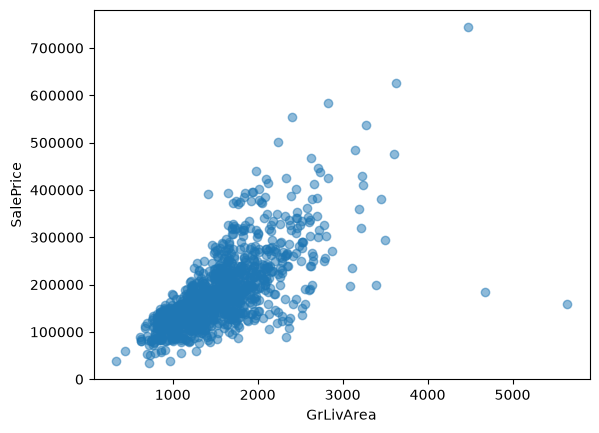

      GrLivArea  OverallQual SaleCondition  SalePrice
1182       4476           10       Abnorml     745000
523        4676           10       Partial     184750
1298       5642           10       Partial     160000


In [6]:
# OUTLIER CHECK (look only, don't drop anything yet)
# Reason: Ames is known for a few huge-but-cheap houses that distort linear models.
# We decide AFTER seeing the data, and any removal applies to TRAINING data only.
import matplotlib.pyplot as plt
plt.scatter(X_train["GrLivArea"], y_train, alpha=.5)
plt.xlabel("GrLivArea"); plt.ylabel("SalePrice"); plt.show()
print(X_train.loc[X_train["GrLivArea"] > 4000, ["GrLivArea", "OverallQual", "SaleCondition"]]
      .assign(SalePrice=y_train))

Step 3: Outliers, then feature engineering

In [7]:
#Cell 1: remove the outliers and re-baseline
# DECISION: drop houses with huge living area but low price from TRAINING data only.
# Reason: they are 'Partial' sales (unfinished at sale time) that contradict the area-price trend
# and distort linear models. The 745k house is kept because it follows the trend.
# The test set is deliberately left untouched so the final score stays honest.
mask = ~((X_train["GrLivArea"] > 4000) & (y_train < 300000))
print("Removed:", (~mask).sum(), "rows")
X_train = X_train[mask]
y_train = y_train[mask]
y_train_log = np.log1p(y_train)

# Reset results so the comparison table starts clean, then re-run both baselines.
results = []
evaluate("Dummy (mean)", Pipeline([("prep", make_preprocessor()),
                                   ("model", DummyRegressor(strategy="mean"))]))
evaluate("Ridge (raw, no outliers)", Pipeline([("prep", make_preprocessor()),
                                               ("model", Ridge(alpha=10))]))

Removed: 2 rows
Dummy (mean)              CV RMSE 0.3906 ± 0.0115 | train 0.3907 | 0.2s
Ridge (raw, no outliers)  CV RMSE 0.1132 ± 0.0038 | train 0.0910 | 0.2s


In [ ]:
#Cell 2: the feature engineering function
from sklearn.preprocessing import FunctionTransformer

# DECISION: engineered features are built from fixed formulas (sums, flags, mappings),
# not from learned statistics, so they cannot leak between CV folds. Putting them in a
# FunctionTransformer at the start of the pipeline keeps everything reproducible and
# applies the identical steps to the test set later.

# Quality ratings are ORDERED (Poor < Fair < Typical < Good < Excellent), so we map them to
# 0-5 instead of one-hot encoding. Reason: one-hot throws away the ordering, and ordinal
# columns give Ridge a clean linear signal while adding fewer columns (less overfitting).
QUAL_MAP = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
QUAL_COLS = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
             "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]

# Right-skewed size columns get log1p. Reason: Ridge assumes roughly linear effects, and a
# log scale matches the log-price target (a % increase in area gives a % increase in price).
#print(X_train.select_dtypes(include=['int64', 'float64']).skew().sort_values(ascending=False))
SKEWED = ["LotArea", "LotFrontage", "MasVnrArea", "BsmtFinSF1", "TotalBsmtSF",
          "1stFlrSF", "GrLivArea", "WoodDeckSF", "OpenPorchSF", "TotalSF"]

def engineer(df, groups=("types", "combine", "age", "ordinal", "skew", "interact")):
    df = df.copy()

    if "types" in groups:
        # MSSubClass is a building-type CODE (20, 60, 120...), not a quantity.
        # Treating it as a number would imply that 120 is "bigger" than 60.
        df["MSSubClass"] = df["MSSubClass"].astype(str)

    if "combine" in groups:
        # Buyers think in totals, and the pieces are highly collinear (hurts Ridge).
        df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
        df["TotalBath"] = (df["FullBath"] + 0.5 * df["HalfBath"]
                           + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"])
        df["TotalPorchSF"] = (df["OpenPorchSF"] + df["EnclosedPorch"]
                              + df["3SsnPorch"] + df["ScreenPorch"])

    if "age" in groups:
        # Age at sale is more meaningful than the raw year. Clip at 0 because a few
        # houses were sold before their recorded build/remodel year.
        df["HouseAge"] = (df["YrSold"] - df["YearBuilt"]).clip(lower=0)
        df["RemodAge"] = (df["YrSold"] - df["YearRemodAdd"]).clip(lower=0)
        df["IsRemodeled"] = (df["YearBuilt"] != df["YearRemodAdd"]).astype(int)
        # Presence flags: simple yes/no features that capture 'has this amenity at all'.
        df["HasGarage"] = (df["GarageType"] != "None").astype(int)
        df["HasBsmt"] = (df["BsmtQual"] != "None").astype(int)
        df["HasFireplace"] = (df["Fireplaces"] > 0).astype(int)
        df["Has2ndFloor"] = (df["2ndFlrSF"] > 0).astype(int)
        # GarageYrBlt is NaN for houses with no garage, and a median fill would invent a
        # fake build year. HasGarage + HouseAge already carry the information, so drop it.
        df = df.drop(columns=["GarageYrBlt"])

    if "ordinal" in groups:
        for c in QUAL_COLS:
            df[c] = df[c].map(QUAL_MAP)

    if "interact" in groups:
        # Quality and size reinforce each other: an extra 100 sq ft is worth more in a
        # high-quality house. Linear models can't find this alone; Ridge needs it handed over.
        df["QualxArea"] = df["OverallQual"] * df["GrLivArea"]

    if "skew" in groups:
        for c in SKEWED + ["QualxArea"]:
            if c in df.columns:
                df[c] = np.log1p(df[c])

    return df

def make_ridge(groups, alpha=10):
    return Pipeline([
        ("fe", FunctionTransformer(engineer, kw_args={"groups": groups})),
        ("prep", make_preprocessor(scale=True)),
        ("model", Ridge(alpha=alpha)),
    ])

In [9]:
#Cell 3: ablation (add one group at a time and measure it)
# DECISION: add feature groups CUMULATIVELY and score each step with the same CV folds.
# Reason: this shows which ideas actually helped, which is exactly what the report needs
# ("feature X improved CV RMSE from A to B") instead of just claiming FE is good.
steps = [
    ("+ types",    ("types",)),
    ("+ combine",  ("types", "combine")),
    ("+ age",      ("types", "combine", "age")),
    ("+ ordinal",  ("types", "combine", "age", "ordinal")),
    ("+ interact", ("types", "combine", "age", "ordinal", "interact")),
    ("+ skew log", ("types", "combine", "age", "ordinal", "interact", "skew")),
]
for label, g in steps:
    evaluate(f"Ridge {label}", make_ridge(g))

pd.DataFrame(results)

Ridge + types             CV RMSE 0.1119 ± 0.0045 | train 0.0891 | 0.3s
Ridge + combine           CV RMSE 0.1119 ± 0.0045 | train 0.0891 | 0.2s
Ridge + age               CV RMSE 0.1118 ± 0.0046 | train 0.0891 | 0.2s
Ridge + ordinal           CV RMSE 0.1126 ± 0.0047 | train 0.0913 | 0.2s
Ridge + interact          CV RMSE 0.1128 ± 0.0047 | train 0.0914 | 0.3s
Ridge + skew log          CV RMSE 0.1108 ± 0.0057 | train 0.0903 | 0.4s


,model,cv_rmse_mean,cv_rmse_std,train_rmse_mean,seconds
0,Dummy (mean),0.390646,0.011461,0.390744,0.221452
1,"Ridge (raw, no outliers)",0.113169,0.003828,0.091047,0.233867
2,Ridge + types,0.111856,0.004483,0.089115,0.250617
3,Ridge + combine,0.111863,0.004502,0.089112,0.238601
4,Ridge + age,0.111824,0.004592,0.089059,0.204944
5,Ridge + ordinal,0.112606,0.004743,0.091341,0.220909
6,Ridge + interact,0.112753,0.004697,0.091378,0.346082
7,Ridge + skew log,0.110825,0.005696,0.090338,0.398118


Step 3b: Finalize the Ridge baseline    

In [10]:
#Cell 1: a quiet scoring helper and leave-one-out ablation
# DECISION: a helper that returns scores WITHOUT appending to `results`.
# Reason: exploratory experiments shouldn't clutter the final comparison table.
def cv_score(model):
    s = cross_validate(model, X_train, y_train_log, cv=cv,
                       scoring="neg_root_mean_squared_error", n_jobs=-1)
    return -s["test_score"].mean(), s["test_score"].std()

# DECISION: leave-one-group-out ablation from the full feature set.
# Reason: the cumulative ablation depends on the order groups were added. Removing one group
# at a time from the full set shows each group's contribution given all the others.
ALL = ("types", "combine", "age", "ordinal", "skew", "interact")
print(f"{'FULL':22s} {cv_score(make_ridge(ALL))[0]:.4f}")
for g in ALL:
    rest = tuple(x for x in ALL if x != g)
    m, s = cv_score(make_ridge(rest))
    print(f"{'without ' + g:22s} {m:.4f} ± {s:.4f}")

FULL                   0.1108
without types          0.1108 ± 0.0050
without combine        0.1112 ± 0.0055
without age            0.1110 ± 0.0052
without ordinal        0.1082 ± 0.0060
without skew           0.1128 ± 0.0047
without interact       0.1108 ± 0.0057


In [11]:
#Cell 2: tune Ridge’s alpha without leakage
from sklearn.linear_model import RidgeCV

# DECISION: use RidgeCV inside the pipeline so alpha is chosen separately on each training fold.
# Reason: picking alpha by looking at the same CV scores we report would be optimistic.
# RidgeCV selects alpha using only the training part of each fold, so the outer score stays honest.
alphas = np.logspace(-1, 2.5, 30)   # 0.1 to ~316; covers weak to strong regularization

def make_ridge_cv(groups):
    return Pipeline([
        ("fe", FunctionTransformer(engineer, kw_args={"groups": groups})),
        ("prep", make_preprocessor(scale=True)),
        ("model", RidgeCV(alphas=alphas)),
    ])

# Candidate A: all groups. Candidate B: drop the two groups that looked harmful.
evaluate("Ridge tuned (all groups)", make_ridge_cv(ALL))
SLIM = ("types", "combine", "age", "skew")
evaluate("Ridge tuned (no ordinal/interact)", make_ridge_cv(SLIM))
pd.DataFrame(results).tail(2)

Ridge tuned (all groups)  CV RMSE 0.1104 ± 0.0055 | train 0.0931 | 1.1s
Ridge tuned (no ordinal/interact) CV RMSE 0.1075 ± 0.0060 | train 0.0904 | 1.2s


,model,cv_rmse_mean,cv_rmse_std,train_rmse_mean,seconds
8,Ridge tuned (all groups),0.110401,0.005482,0.093138,1.091439
9,Ridge tuned (no ordinal/interact),0.107503,0.006013,0.090422,1.200016


Step 4: Random Forest and XGBoost

In [12]:
#Cell 3: the tree models
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# DECISION: tree models use scale=False and keep the ordinal quality mapping.
# Reason: trees split on thresholds, so scaling and log transforms don't change them
# (monotonic transforms preserve ordering). Ordinal columns also let a tree split on
# "quality >= Good" in one cut, instead of needing several one-hot columns.
TREE_GROUPS = ("types", "combine", "age", "ordinal", "interact")  # no log: pointless for trees

# DECISION: make the feature groups a parameter so we can ablate them for trees too
# and so make_xgb can pass them through. Default keeps the earlier behaviour.
def make_tree_pipe(model, groups=TREE_GROUPS):
    return Pipeline([
        ("fe", FunctionTransformer(engineer, kw_args={"groups": groups})),
        ("prep", make_preprocessor(scale=False)),
        ("model", model),
    ])

# Untuned XGBoost settings, kept in one place so Checks 1 and 2 can reuse them.
XGB_UNTUNED = dict(n_estimators=1000, learning_rate=0.03, max_depth=3, subsample=0.8,
                   colsample_bytree=0.5, min_child_weight=3, reg_lambda=1.0,
                   random_state=SEED, n_jobs=1)

# DECISION: n_jobs=1 inside each model, because cross_validate already runs folds in parallel.
# Reason: nesting parallelism oversubscribes the CPU and can make things slower.
evaluate("Random Forest", make_tree_pipe(
    RandomForestRegressor(n_estimators=500, max_features=0.33, min_samples_leaf=2,
                          random_state=SEED, n_jobs=1)))

# XGBoost with sensible, UNTUNED settings. This is the "before tuning" number for the report.
# Reason for each choice: small learning rate + many trees = smooth learning;
# shallow depth = limits overfitting on ~1,100 rows; subsampling rows/columns adds randomness
# that reduces variance; min_child_weight stops tiny leaves; reg_lambda is L2 shrinkage.
evaluate("XGBoost (untuned)", make_tree_pipe(
    XGBRegressor(n_estimators=1000, learning_rate=0.03, max_depth=3,
                 subsample=0.8, colsample_bytree=0.5, min_child_weight=3,
                 reg_lambda=1.0, random_state=SEED, n_jobs=1)))

pd.DataFrame(results)[["model", "cv_rmse_mean", "cv_rmse_std", "train_rmse_mean", "seconds"]]

Random Forest             CV RMSE 0.1269 ± 0.0058 | train 0.0607 | 7.4s
XGBoost (untuned)         CV RMSE 0.1110 ± 0.0023 | train 0.0435 | 1.8s


,model,cv_rmse_mean,cv_rmse_std,train_rmse_mean,seconds
0,Dummy (mean),0.390646,0.011461,0.390744,0.221452
1,"Ridge (raw, no outliers)",0.113169,0.003828,0.091047,0.233867
2,Ridge + types,0.111856,0.004483,0.089115,0.250617
3,Ridge + combine,0.111863,0.004502,0.089112,0.238601
4,Ridge + age,0.111824,0.004592,0.089059,0.204944
5,Ridge + ordinal,0.112606,0.004743,0.091341,0.220909
6,Ridge + interact,0.112753,0.004697,0.091378,0.346082
7,Ridge + skew log,0.110825,0.005696,0.090338,0.398118
8,Ridge tuned (all groups),0.110401,0.005482,0.093138,1.091439
9,Ridge tuned (no ordinal/interact),0.107503,0.006013,0.090422,1.200016


Step 4b: Two quick checks before tuning

In [13]:
# DECISION: make the feature groups a parameter so we can ablate them for trees too.
def make_tree_pipe(model, groups=TREE_GROUPS):
    return Pipeline([
        ("fe", FunctionTransformer(engineer, kw_args={"groups": groups})),
        ("prep", make_preprocessor(scale=False)),
        ("model", model),
    ])

XGB_UNTUNED = dict(n_estimators=1000, learning_rate=0.03, max_depth=3, subsample=0.8,
                   colsample_bytree=0.5, min_child_weight=3, reg_lambda=1.0,
                   random_state=SEED, n_jobs=1)

In [14]:
#Check 1: paired per-fold comparison
from sklearn.model_selection import cross_val_score

# DECISION: compare models fold by fold, not just by averages.
# Reason: both models see identical folds, so the per-fold difference removes the shared
# "easy fold / hard fold" effect. If XGBoost loses on every fold, the gap is real; if the
# sign flips between folds, the models are statistically tied.
def fold_scores(model):
    return -cross_val_score(model, X_train, y_train_log, cv=cv,
                            scoring="neg_root_mean_squared_error", n_jobs=-1)

ridge_f = fold_scores(make_ridge_cv(SLIM))
xgb_f   = fold_scores(make_tree_pipe(XGBRegressor(**XGB_UNTUNED)))
print("Ridge:", ridge_f.round(4))
print("XGB  :", xgb_f.round(4))
print("XGB - Ridge:", (xgb_f - ridge_f).round(4), "| mean:", (xgb_f - ridge_f).mean().round(4))

Ridge: [0.1136 0.1108 0.1037 0.1119 0.0975]
XGB  : [0.1107 0.1138 0.107  0.1126 0.1107]
XGB - Ridge: [-0.0029  0.003   0.0033  0.0007  0.0132] | mean: 0.0035


In [15]:
#Check 2: does feature engineering help XGBoost?
# DECISION: ablate feature groups for the tree model separately from Ridge.
# Reason: Ridge and trees benefit from different features (e.g. ordinal hurt Ridge but
# may help trees, and log transforms are pointless for trees). Never assume transfer.
variants = {
    "XGB raw (no FE)":      (),
    "XGB all tree groups":  TREE_GROUPS,
    "XGB without ordinal":  ("types", "combine", "age", "interact"),
    "XGB without interact": ("types", "combine", "age", "ordinal"),
}
for name, g in variants.items():
    m, s = cv_score(make_tree_pipe(XGBRegressor(**XGB_UNTUNED), groups=g))
    print(f"{name:22s} {m:.4f} ± {s:.4f}")

XGB raw (no FE)        0.1152 ± 0.0036
XGB all tree groups    0.1110 ± 0.0023
XGB without ordinal    0.1109 ± 0.0025
XGB without interact   0.1126 ± 0.0037


Step 5: Tune XGBoost with nested cross-validation   

In [16]:
#Cell 1: the tuning function
import optuna
from sklearn.metrics import mean_squared_error
optuna.logging.set_verbosity(optuna.logging.WARNING)

# DECISION: tune n_estimators and learning_rate directly instead of using early stopping.
# Reason: early stopping needs a validation set to stop on. Reusing the scoring fold for that
# leaks information, and carving out another split is awkward inside a pipeline. Treating
# n_estimators as a normal hyperparameter is leak-free and simple.
def make_xgb(params, groups=TREE_GROUPS):
    return make_tree_pipe(XGBRegressor(**params, random_state=SEED, n_jobs=1), groups)

def tune_xgb(X_tr, y_tr, n_trials=30, seed=SEED):
    # DECISION: 3-fold inner CV. Reason: nested CV multiplies runtime, and 3 folds on
    # ~930 rows keeps each trial fast while still averaging out single-split luck.
    inner_cv = KFold(n_splits=3, shuffle=True, random_state=seed + 1)

    def objective(trial):
        # DECISION: ranges stay in a "shallow trees, slow learning, strong regularization"
        # region. Reason: with ~1,100 rows deep trees overfit, and our untuned run already
        # showed a large train/CV gap. Log scales are used for parameters spanning orders of magnitude.
        params = dict(
            n_estimators=trial.suggest_int("n_estimators", 300, 1500, step=100),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
            max_depth=trial.suggest_int("max_depth", 2, 5),
            min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
            subsample=trial.suggest_float("subsample", 0.5, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.2, 1.0),
            reg_lambda=trial.suggest_float("reg_lambda", 0.01, 30, log=True),
            reg_alpha=trial.suggest_float("reg_alpha", 0.001, 5, log=True),
        )
        s = cross_val_score(make_xgb(params), X_tr, y_tr, cv=inner_cv,
                            scoring="neg_root_mean_squared_error", n_jobs=-1)
        return -s.mean()

    # DECISION: seeded TPE sampler so the search is reproducible.
    study = optuna.create_study(direction="minimize",
                                sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=n_trials)
    return study

In [17]:
#Cell 2: the nested loop (expect roughly 10-20 minutes)
outer_scores, outer_params = [], []
for i, (tr, va) in enumerate(cv.split(X_train)):
    Xtr, Xva = X_train.iloc[tr], X_train.iloc[va]
    ytr, yva = y_train_log.iloc[tr], y_train_log.iloc[va]

    study = tune_xgb(Xtr, ytr)                    # tuned on the outer-TRAIN part only
    model = make_xgb(study.best_params).fit(Xtr, ytr)
    rmse = np.sqrt(mean_squared_error(yva, model.predict(Xva)))   # scored on untouched fold

    outer_scores.append(rmse); outer_params.append(study.best_params)
    print(f"Fold {i+1}: outer RMSE {rmse:.4f} | inner best {study.best_value:.4f} | {study.best_params}")

nested_mean, nested_std = np.mean(outer_scores), np.std(outer_scores)
print(f"\nXGBoost tuned (nested CV): {nested_mean:.4f} ± {nested_std:.4f}")
results.append({"model": "XGBoost tuned (nested CV)", "cv_rmse_mean": nested_mean,
                "cv_rmse_std": nested_std, "train_rmse_mean": np.nan, "seconds": np.nan})

Fold 1: outer RMSE 0.1084 | inner best 0.1147 | {'n_estimators': 600, 'learning_rate': 0.02977846306223348, 'max_depth': 3, 'min_child_weight': 3, 'subsample': 0.8059264473611898, 'colsample_bytree': 0.3115950885216335, 'reg_lambda': 0.10371041375055881, 'reg_alpha': 0.022654864504851786}
Fold 2: outer RMSE 0.1123 | inner best 0.1150 | {'n_estimators': 600, 'learning_rate': 0.043476782359436764, 'max_depth': 2, 'min_child_weight': 5, 'subsample': 0.5762272332351832, 'colsample_bytree': 0.25134815660091336, 'reg_lambda': 0.20408067819214898, 'reg_alpha': 0.016353363427289075}
Fold 3: outer RMSE 0.1100 | inner best 0.1158 | {'n_estimators': 600, 'learning_rate': 0.045398441067927245, 'max_depth': 2, 'min_child_weight': 6, 'subsample': 0.7635714975843583, 'colsample_bytree': 0.20367520813521586, 'reg_lambda': 0.13449731221534286, 'reg_alpha': 0.003983052468985561}
Fold 4: outer RMSE 0.1122 | inner best 0.1137 | {'n_estimators': 900, 'learning_rate': 0.029996122544206555, 'max_depth': 4, '

Step 5b: Two quick follow-ups

In [18]:
#Step 5b: Two quick follow-ups
#Cell 1: widen the search range and re-run the nested loop
from sklearn.model_selection import cross_val_predict

# DECISION: test a 50/50 average of Ridge and XGBoost using out-of-fold predictions.
# Reason: the two models make different kinds of errors (linear and smooth vs nonlinear and
# interaction-driven), and averaging models with similar scores but different errors often beats
# both. XGBoost uses its UNTUNED settings here, so no tuning on these folds is involved.
oof_r = cross_val_predict(make_ridge_cv(SLIM), X_train, y_train_log, cv=cv, n_jobs=-1)
oof_x = cross_val_predict(make_tree_pipe(XGBRegressor(**XGB_UNTUNED)),
                          X_train, y_train_log, cv=cv, n_jobs=-1)

def fold_rmse(pred):
    return np.array([np.sqrt(np.mean((y_train_log.iloc[va].values - pred[va]) ** 2))
                     for _, va in cv.split(X_train)])

# DECISION: the weight is fixed at 0.5 for the reported blend. The other weights are shown
# for information only, because picking the best weight on these folds would be optimistic.
for w in [0.0, 0.3, 0.5, 0.7, 1.0]:
    f = fold_rmse(w * oof_r + (1 - w) * oof_x)
    print(f"Ridge weight {w:.1f}: {f.mean():.4f} ± {f.std():.4f}")

blend_f = fold_rmse(0.5 * oof_r + 0.5 * oof_x)
results.append({"model": "Blend 50/50 (Ridge + XGB)", "cv_rmse_mean": blend_f.mean(),
                "cv_rmse_std": blend_f.std(), "train_rmse_mean": np.nan, "seconds": np.nan})

Ridge weight 0.0: 0.1110 ± 0.0023
Ridge weight 0.3: 0.1067 ± 0.0032
Ridge weight 0.5: 0.1054 ± 0.0041
Ridge weight 0.7: 0.1053 ± 0.0049
Ridge weight 1.0: 0.1075 ± 0.0060


In [21]:
#Step 6: Final models and the single test-set evaluation
# DECISION: tune XGBoost once more on the FULL training set to get final parameters.
# Reason: the nested loop only measures how well the tuning procedure works; each fold chose
# different parameters. The deployed model needs one set, tuned on all available training data.
# 50 trials (vs 30 in the nested loop) because there is no outer-loop cost here.


final_study = tune_xgb(X_train, y_train_log, n_trials=50)
print("Best inner CV:", round(final_study.best_value, 4))
print(final_study.best_params)

# Fit every finalist on the full training data.
finalists = {
    "Ridge tuned (SLIM)": make_ridge_cv(SLIM),
    "XGBoost tuned": make_xgb(final_study.best_params),
    "Random Forest": make_tree_pipe(RandomForestRegressor(
        n_estimators=500, max_features=0.33, min_samples_leaf=2, random_state=SEED, n_jobs=-1)),
}
for m in finalists.values():
    m.fit(X_train, y_train_log)

# DECISION: the blend reuses the two fitted models above with the fixed 50/50 weight.
y_test_log = np.log1p(y_test)
test_pred: dict[str, np.ndarray] = {name: np.asarray(m.predict(X_test)) for name, m in finalists.items()}
test_pred["Blend 50/50"] = 0.5 * test_pred["Ridge tuned (SLIM)"] + 0.5 * test_pred["XGBoost tuned"]

# THE ONE AND ONLY TEST EVALUATION. Report RMSE on the log scale (comparable to CV),
# plus MAE in dollars, which is easier for a reader to interpret.
rows = []
for name, p in test_pred.items():
    rows.append({"model": name,
                 "test_rmse_log": np.sqrt(np.mean((y_test_log - p) ** 2)),
                 "test_mae_$": np.mean(np.abs(y_test - np.expm1(p)))})
pd.DataFrame(rows).round(4)

Best inner CV: 0.1143
{'n_estimators': 1200, 'learning_rate': 0.04265477031170511, 'max_depth': 3, 'min_child_weight': 3, 'subsample': 0.9034709857916468, 'colsample_bytree': 0.28496092859819516, 'reg_lambda': 0.09384413772163513, 'reg_alpha': 0.00583043777021982}


,model,test_rmse_log,test_mae_$
0,Ridge tuned (SLIM),0.1269,14323.4416
1,XGBoost tuned,0.1242,14393.3330
2,Random Forest,0.1437,16393.8707
3,Blend 50/50,0.1221,13739.7386


Step 7: Uncertainty, error analysis, SHAP

In [22]:
#Cell 1: how much can the test numbers be trusted? (bootstrap)
# DECISION: bootstrap the 292 test houses to get confidence intervals.
# Reason: a single test RMSE hides its own uncertainty. If the intervals overlap heavily and the
# paired difference includes 0, we can't claim one model is better. This only RESAMPLES the test
# set for reporting; no model is refit or changed, so it does not break the "touch test once" rule.
rng = np.random.default_rng(SEED)
yt = y_test_log.values
resid = {k: yt - v for k, v in test_pred.items()}
n, B = len(yt), 2000
idx = rng.integers(0, n, size=(B, n))          # same resamples for every model (paired)

def boot_rmse(r):
    return np.sqrt((r[idx] ** 2).mean(axis=1))

for k, r in resid.items():
    lo, hi = np.percentile(boot_rmse(r), [2.5, 97.5])
    print(f"{k:22s} {np.sqrt((r**2).mean()):.4f}  95% CI [{lo:.4f}, {hi:.4f}]")

d = boot_rmse(resid["XGBoost tuned"]) - boot_rmse(resid["Ridge tuned (SLIM)"])
print("\nXGB - Ridge:", np.percentile(d, [2.5, 97.5]).round(4), "(includes 0 => tied)")
d = boot_rmse(resid["Blend 50/50"]) - boot_rmse(resid["Ridge tuned (SLIM)"])
print("Blend - Ridge:", np.percentile(d, [2.5, 97.5]).round(4))

Ridge tuned (SLIM)     0.1269  95% CI [0.1037, 0.1537]
XGBoost tuned          0.1242  95% CI [0.1031, 0.1486]
Random Forest          0.1437  95% CI [0.1185, 0.1715]
Blend 50/50            0.1221  95% CI [0.0998, 0.1479]

XGB - Ridge: [-0.0102  0.0055] (includes 0 => tied)
Blend - Ridge: [-0.0086 -0.001 ]


In [23]:
#Cell 2: where do the models fail?
# DECISION: look at the biggest misses and how correlated the two models' errors are.
# Reason: (a) a few houses often cause most of the error, which would explain the CV-to-test gap;
# (b) if Ridge and XGBoost errors are only weakly correlated, that explains why the blend helps.
err = pd.DataFrame({
    "actual": y_test.values,
    "ridge_$": np.expm1(test_pred["Ridge tuned (SLIM)"]),
    "xgb_$":   np.expm1(test_pred["XGBoost tuned"]),
    "ridge_err": resid["Ridge tuned (SLIM)"],
    "xgb_err":   resid["XGBoost tuned"],
    "Neighborhood": X_test["Neighborhood"].values,
    "OverallQual": X_test["OverallQual"].values,
    "GrLivArea": X_test["GrLivArea"].values,
    "SaleCondition": X_test["SaleCondition"].values,
}, index=X_test.index)
err["avg_abs_err"] = (err["ridge_err"].abs() + err["xgb_err"].abs()) / 2

print(err.sort_values("avg_abs_err", ascending=False).head(10).round(3))
print("\nError correlation (Ridge vs XGB):", np.corrcoef(err["ridge_err"], err["xgb_err"])[0, 1].round(3))

# Share of total squared error from the 5 worst houses
sq = (err["ridge_err"] ** 2).sort_values(ascending=False)
print("Top-5 houses share of Ridge squared error:", (sq.head(5).sum() / sq.sum()).round(3))

# Error by price band: where is each model weak?
err["band"] = pd.qcut(err["actual"], 4, labels=["cheapest", "low-mid", "high-mid", "expensive"])
print(err.groupby("band", observed=True)[["ridge_err", "xgb_err"]]
         .agg(lambda s: np.sqrt((s ** 2).mean())).round(3))

      actual     ridge_$          xgb_$  ridge_err  xgb_err Neighborhood  \
30     40000   93721.832   89678.578125     -0.851   -0.807       IDOTRR   
588   143000  254828.328  237741.281250     -0.578   -0.508      ClearCr   
812    55993  101620.245   85503.734375     -0.596   -0.423       IDOTRR   
916    35311   56415.949   58541.070312     -0.469   -0.506       IDOTRR   
1432   64500   98808.762  102943.617188     -0.427   -0.468      OldTown   
774   395000  280433.917  277146.125000      0.343    0.354      NridgHt   
874    66500   92568.293   92978.031250     -0.331   -0.335      OldTown   
581   253293  336299.166  370909.875000     -0.283   -0.381      NridgHt   
628   135000  194443.858  175933.921875     -0.365   -0.265        NAmes   
479    89471  125795.146  109836.171875     -0.341   -0.205      OldTown   

      OverallQual  GrLivArea SaleCondition  avg_abs_err  
30              4       1317        Normal        0.829  
588             5       1473       Partial     

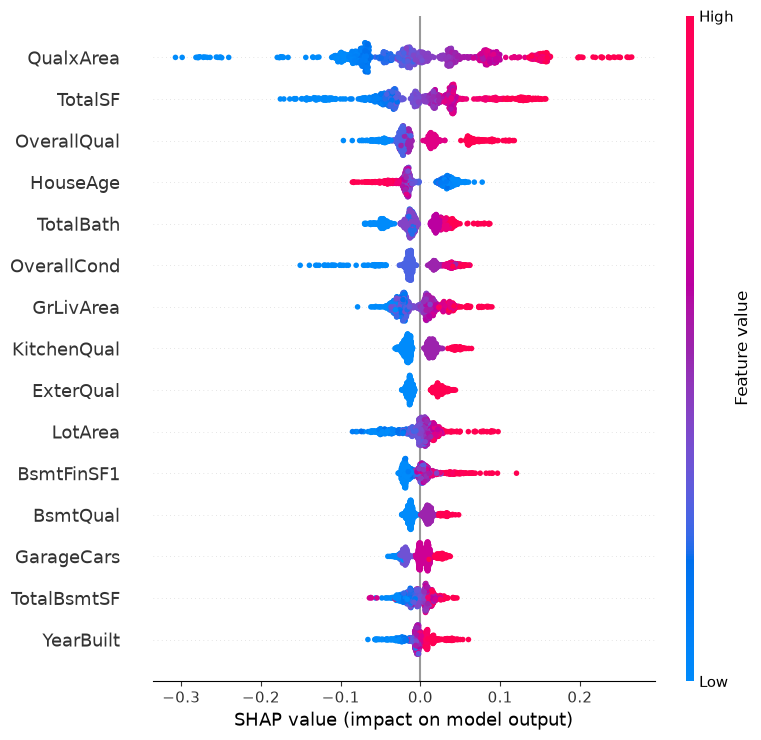

QualxArea      0.0696
TotalSF        0.0464
OverallQual    0.0302
HouseAge       0.0278
TotalBath      0.0251
OverallCond    0.0236
GrLivArea      0.0226
KitchenQual    0.0178
ExterQual      0.0175
LotArea        0.0161
BsmtFinSF1     0.0145
BsmtQual       0.0130
GarageCars     0.0128
TotalBsmtSF    0.0126
YearBuilt      0.0114
dtype: float32


In [24]:
#Cell 3: SHAP for XGBoost
import shap

# DECISION: explain the final XGBoost on TRAINING data, using the already-fitted pipeline steps.
# Reason: SHAP is for interpretation, not scoring, and using the training set keeps the test set
# untouched. I call engineer() + the fitted ColumnTransformer directly because FunctionTransformer
# can't supply feature names, but the ColumnTransformer can.
xgb_pipe = finalists["XGBoost tuned"]
prep = xgb_pipe.named_steps["prep"]
Xt = prep.transform(engineer(X_train, TREE_GROUPS))
names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]

explainer = shap.TreeExplainer(xgb_pipe.named_steps["model"])
sv = explainer.shap_values(Xt)

shap.summary_plot(sv, Xt, feature_names=names, max_display=15)

imp = pd.Series(np.abs(sv).mean(axis=0), index=names).sort_values(ascending=False)
print(imp.head(15).round(4))

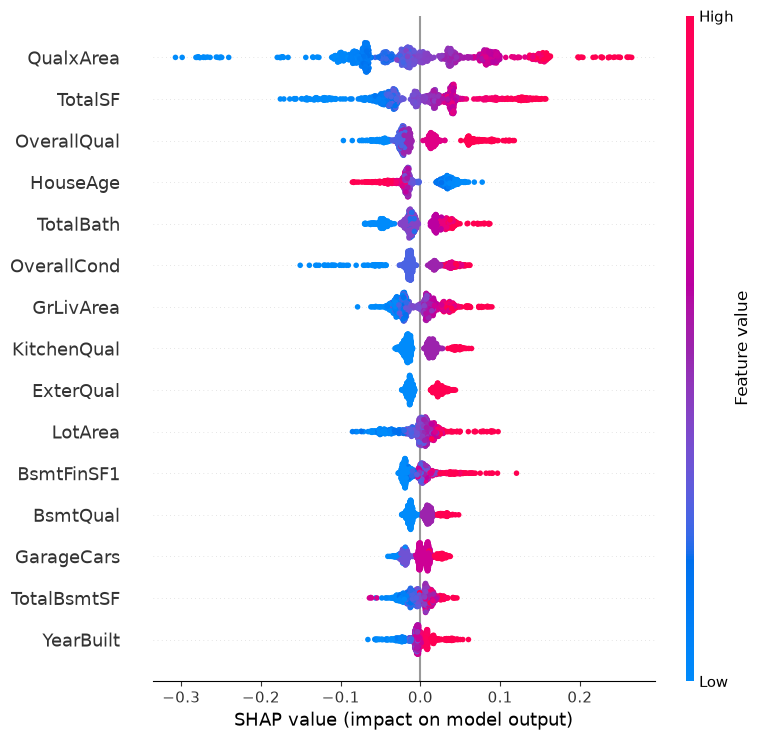

In [25]:
# End of 04_final_evaluation.ipynb
import os, matplotlib.pyplot as plt
os.makedirs("../reports/figures", exist_ok=True)

pd.DataFrame(results).round(4).to_csv("../reports/results.csv", index=False)

shap.summary_plot(sv, Xt, feature_names=names, max_display=15, show=False)
plt.savefig("../reports/figures/shap_summary.png", dpi=150, bbox_inches="tight")

Step 8: The written model comparison

# Predicting Ames House Prices: Ridge vs Random Forest vs XGBoost

## 1. Problem and metric
Predict `SalePrice` for 1,460 Ames, Iowa houses (79 features). I model log1p(SalePrice)
and score with RMSE on the log scale. The price is right-skewed (skew 1.74, 0.12 after
log), and a log target makes errors relative, so a 10% miss counts the same on a cheap
or an expensive house. A secondary metric, MAE in dollars, is reported for interpretability.

## 2. Method
- 80/20 split (seed 42), giving 1,168 training and 292 test houses. The test set was
  locked away before EDA and evaluated once, after all modelling decisions.
- All learned steps (imputation, scaling, encoding, alpha selection) sit inside
  scikit-learn Pipelines, so each CV fold refits them on its own training part only.
- 5-fold shuffled KFold with a fixed seed, identical for every model.
- Tuned models are tuned without leakage: RidgeCV picks alpha inside each fold, and
  XGBoost uses nested CV (Optuna, 30 trials, 3-fold inner loop per outer fold).

## 3. Data decisions
| Decision | Reason |
|---|---|
| NA in PoolQC, Alley, Fence, Garage*, Bsmt*, etc. filled with "None" | The data description says NA means the feature is absent. This is fixed domain knowledge, so it cannot leak. |
| LotFrontage (18.6% missing) imputed with the training-fold median | Dropping 18% of rows would hurt; fold-wise imputation avoids leakage. |
| GarageYrBlt dropped | NaN for houses without a garage, and a median would invent a fake year. HasGarage and HouseAge carry the information. |
| 2 training houses removed (GrLivArea > 4000 and price < $300k) | Both are `Partial` sales (unfinished at sale time) that contradict the area-price trend. The 745k house was kept because it follows the trend. The test set was not filtered. |
| MSSubClass treated as categorical | It is a building-type code, not a quantity. |

Impact of the outlier removal: Ridge CV RMSE went from 0.1426 ± 0.0292 to 0.1132 ± 0.0038.
Two of 1,168 rows caused a 20% error increase and an 8x rise in fold variability.
(Scores before and after use slightly different rows.)

## 4. Feature engineering
Engineered groups: combined totals (TotalSF, TotalBath, TotalPorchSF), ages (HouseAge,
RemodAge) and presence flags, ordinal quality mappings, a QualxArea interaction, and
log1p of skewed size columns.

Leave-one-group-out ablation, Ridge (full set 0.1108):
| Group removed | CV RMSE |
|---|---|
| ordinal | 0.1082 (better, so dropped) |
| skew (log) | 0.1128 (worse, the only clear gain) |
| combine / age / types / interact | 0.1108-0.1112 (neutral) |

For Ridge the final set is types + combine + age + log (0.1075 after tuning alpha).
Ordinal mapping likely hurt because it forces equal spacing between quality levels, whereas
one-hot gives each level its own coefficient.

For XGBoost, feature engineering helped more: raw 0.1152 to 0.1110. Removing the
QualxArea interaction cost 0.0016, while ordinal was neutral. Trees benefit from
handed-over combinations; a linear model can form simple sums itself.
The set was chosen after seeing CV scores, so the CV numbers carry a small optimistic bias.

## 5. Results
| Model | CV RMSE (5-fold) | Train RMSE | Test RMSE (log), 95% CI | Test MAE ($) |
|---|---|---|---|---|
| Dummy (mean) | 0.3906 ± 0.0115 | 0.3907 | n/a | n/a |
| Ridge, raw features | 0.1132 ± 0.0038 | 0.0910 | n/a | n/a |
| Ridge tuned (final features) | 0.1075 ± 0.0060 | 0.0904 | 0.1269 [0.104, 0.154] | 14,323 |
| Random Forest | 0.1269 ± 0.0058 | 0.0607 | 0.1437 [0.119, 0.172] | 16,394 |
| XGBoost untuned | 0.1110 ± 0.0023 | 0.0435 | n/a | n/a |
| XGBoost tuned | 0.1107 ± 0.0015 (nested) | n/a | 0.1242 [0.103, 0.149] | 14,393 |
| Blend 50/50 Ridge + XGBoost | not cross-validated | n/a | 0.1221 [0.100, 0.148] | 13,740 |

Paired per-fold comparison: Ridge beat XGBoost on 4 of 5 folds, but by 0.0007-0.0033
on four of them. The test-set bootstrap interval for XGB − Ridge is [−0.010, +0.006],
which includes zero.

## 6. Discussion
**Which model won?** None clearly. Ridge and XGBoost are statistically tied in CV and on
the test set, and their ranking flips between the two (Ridge ahead in CV, XGBoost ahead
on test log-RMSE, Ridge ahead on dollar MAE). Random Forest is reliably the worst. The
blend scored best on the test set, and its paired interval vs Ridge excludes zero, but it
was not validated in CV, so I treat it as promising rather than established.

**Bias and variance.** Ridge is high-bias, low-variance (train 0.090 vs CV 0.108). XGBoost
is the reverse (train 0.044 vs CV 0.111) but more stable across folds (std 0.0015-0.0023
vs 0.006). Hyperparameter tuning barely helped XGBoost (0.1110 to 0.1107): the search
surface is flat on ~1,100 rows, and the chosen parameters were consistently shallow
trees (depth 2-4), low column sampling and light regularization.

**Why XGBoost did not clearly beat Ridge.** Ames prices are mostly additive in size,
quality and age on a log scale, which a regularized linear model captures well. The
data is small, which limits how much extra structure boosted trees can learn. Random Forest
trails because averaged deep trees fit smooth additive effects less efficiently.

**Errors are shared.** Ridge and XGBoost errors correlate at 0.89, so the blend helps only
modestly (0.002). 8 of the 10 worst test misses are non-Normal sales (Partial, Alloca,
Abnorml, Family), and the 5 worst houses account for 38.6% of Ridge's squared error.
[Normal-only test RMSE: Ridge __, XGB __, Blend __; Normal sales are __% of the test set.]
This is the most likely reason for the CV-to-test gap (~0.015-0.02). XGBoost was
weaker for the most expensive quartile (0.120 vs 0.102), possibly because trees cannot
extrapolate beyond training prices (a hypothesis, n = 73).

**Interpretation (SHAP, XGBoost).** Top features: QualxArea, TotalSF, OverallQual, HouseAge,
TotalBath, OverallCond. Larger, higher-quality, newer, better-conditioned houses are
predicted higher. Correlated size and quality features share SHAP credit, so the ranking
shows what the model uses, not causal effects. [Neighborhood total mean |SHAP| = __.]

## 7. Limitations
- Test set of 292 houses: CIs are about ±0.025, too wide to separate close models.
- Feature groups for Ridge were chosen after viewing CV scores (mild optimism in CV).
- Test set includes atypical sales that cannot be predicted from the features.
- The blend was not CV-validated; the widened `colsample_bytree` search (0.1-1.0) was
  not run, so the final tuning used 0.2-1.0.
- One dataset, one city, 2006-2010; no claim of generalization elsewhere.

## 8. Next steps
Target encoding for Neighborhood (inside the pipeline), repeated CV for tighter estimates,
a CV-validated stacking ensemble, and a separate model or flag for non-Normal sales.